In [ ]:
## 1. Implement the naive algorithm of Lecture 12: for every
## ordering of the reads, merge them left to right using the longest suffix–prefix overlap, and
## keep the shortest result.

In [1]:
from itertools import permutations

def SCS_founder(reads):
    superstrings_lengths = {}
    for p in (permutations(reads)):
        concat = p[0]
        n = len(reads)
        frag_len = len(p[0])
        for i in range(n-1):
            if p[i] == p[i+1]:
                print("Error, the algorithm assumes no read is a complete substring of another")
            ov = 0
            for k in range(1, frag_len):
                if p[i][-k:] == p[i+1][:k]:
                    ov = k
            s = p[i+1][ov:]
            concat = concat + s 
        len_substring = len(concat)
        superstrings_lengths[p] = len_substring
    min_key, min_val = min(superstrings_lengths.items(), key=lambda item: item[1])
    return (f"Key: {min_key}, Value: {min_val}")

print(SCS_founder(["ACGT", "CGTA", "GTAC", "TACG"]))

Key: ('ACGT', 'CGTA', 'GTAC', 'TACG'), Value: 7


In [7]:
## Run it on random sets of n reads of length 8 drawn from a
## random genome of length 30, for n from 4 to 9, timing each run. Plot time against n and
## estimate the growth.

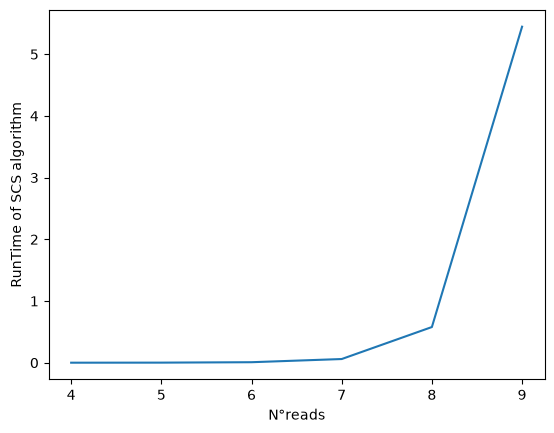

None


In [3]:
import random
import time
%matplotlib inline
import matplotlib.pyplot as plt 

def random_run_SCS():
    time_store = []
    t0 = time.time()
    read = []
    genome = ""
    random.seed(1120)
    for i in range(30):
        genome = genome + random.choice(["A", "C", "T", "G"])
    for i in range(4,10):
        read = []
        for j in range(i):
            read.append("".join(random.choices(genome, k=8)))
        scs = SCS_founder(read)
        time_store.append(time.time()- t0)

    x = [4, 5, 6, 7, 8, 9]
    y = time_store 

    plt.plot(x, y)
    plt.xlabel("N°reads")
    plt.ylabel("RunTime of SCS algorithm")
    plt.show()  

print(random_run_SCS())

In [ ]:
## Then implement an exact algorithm that runs in O(2^n*n^2) time by
## dynamic programming over subsets of reads, with the last read placed as the state (after
## first discarding any read contained in another).

In [4]:
from itertools import combinations

def SCS_founder_DP(reads):
    clean_reads = []
    for r1 in reads:
        is_sub = False
        for r2 in reads:
            if r1 != r2 and r1 in r2:
                is_sub = True
        if not is_sub and r1 not in clean_reads:
            clean_reads.append(r1)
    reads = clean_reads
    n = len(reads)

    dp = {}
    for r in reads:
        dp[(frozenset([r]), r)] = r

    for size in range(1, n):
        for subset in combinations(reads, size):
            subset = frozenset(subset)
            for last in subset:
                concat = dp[(subset, last)]
                for nxt in reads:
                    if nxt not in subset:
                        new_subset = subset | {nxt}
                        
                        # Find largest overlap between end of concat and start of nxt
                        ov = 0
                        for k in range(1, min(len(last), len(nxt)) + 1):
                            if last[-k:] == nxt[:k]:
                                ov = k
                        
                        new_concat = concat + nxt[ov:]
                        if (new_subset, nxt) not in dp or len(new_concat) < len(dp[(new_subset, nxt)]):
                            dp[(new_subset, nxt)] = new_concat

    # Collect final results using all reads, matching your return style
    full_set = frozenset(reads)
    superstrings_lengths = {}
    for r in reads:
        s = dp[(full_set, r)]
        superstrings_lengths[s] = len(s)

    min_key, min_val = min(superstrings_lengths.items(), key=lambda item: item[1])
    return (f"Key: {min_key}, Value: {min_val}")

In [5]:
genome = ""
random.seed(1120)
for i in range(30):
    genome = genome + random.choice(["A", "C", "T", "G"])

for i in range(4, 10):
    read = []
    for j in range(i):
        read.append("".join(random.choices(genome, k=8)))
    
    len_perm = int(SCS_founder(read).split("Value: ")[1])
    len_dp = int(SCS_founder_DP(read).split("Value: ")[1])
    print(f"n={i} -> Permutation: {len_perm}, DP: {len_dp}, Match: {len_perm == len_dp}")

# --- PART B: Find the largest n DP handles in under 1 minute ---
time_store = []
max_n_under_60s = 0

for i in range(4, 22):
    read = []
    for j in range(i):
        # Sampling from a longer genome avoids accidental duplicate 8-mers
        read.append("".join(random.choices(["A", "C", "T", "G"], k=8)))
    
    t0 = time.time()   # Placed INSIDE the loop to measure each 'i' individually
    scs = SCS_founder_DP(read)
    elapsed = time.time() - t0
    time_store.append(elapsed)
    
    print(f"n={i}: {elapsed:.4f} seconds")
    if elapsed < 60:
        max_n_under_60s = i
    else:
        print(f"Stopped: n={i} took longer than 1 minute.")
        break

print(f"\nLargest n handled in under 1 minute: {max_n_under_60s}")

n=4 -> Permutation: 29, DP: 29, Match: True
n=5 -> Permutation: 36, DP: 36, Match: True
n=6 -> Permutation: 42, DP: 42, Match: True
n=7 -> Permutation: 45, DP: 45, Match: True
n=8 -> Permutation: 51, DP: 51, Match: True
n=9 -> Permutation: 60, DP: 60, Match: True
n=4: 0.0001 seconds
n=5: 0.0003 seconds
n=6: 0.0010 seconds
n=7: 0.0027 seconds
n=8: 0.0084 seconds
n=9: 0.0207 seconds
n=10: 0.0570 seconds
n=11: 0.1820 seconds
n=12: 0.4068 seconds
n=13: 0.7926 seconds
n=14: 1.9909 seconds
n=15: 4.8318 seconds
n=16: 11.5202 seconds
n=17: 25.4514 seconds
n=18: 57.9933 seconds
n=19: 131.0626 seconds
Stopped: n=19 took longer than 1 minute.

Largest n handled in under 1 minute: 18


In [12]:
print("Brute force Time Complexity --> Θ(n! · n · L) (O(n · L²) per permutation if slicing is counted)")
print("Brute force Space Complexity --> O(n · 2ⁿ · L), since full strings are stored per state")
print("")
print("DP Time Complexity --> O(n² · 2ⁿ · L²)")
print("DP Space Complexity --> O(n!) dictionary entries")
print("")
print("Brute force explores all n! orderings of the reads, while the DP only explores n · 2ⁿ (subset, last read) states")
print("So n! is super-exponential (~nⁿ, growing base), whereas 2ⁿ is a true single-exponential (fixed base);")
print("both stay exponential because shortest common superstring is NP-hard, as in TSP versus Held-Karp.")

Brute force Time Complexity --> Θ(n! · n · L) (O(n · L²) per permutation if slicing is counted)
Brute force Space Complexity --> O(n · 2ⁿ · L), since full strings are stored per state

DP Time Complexity --> O(n² · 2ⁿ · L²)
DP Space Complexity --> O(n!) dictionary entries

Brute force explores all n! orderings of the reads, while the DP only explores n · 2ⁿ (subset, last read) states
So n! is super-exponential (~nⁿ, growing base), whereas 2ⁿ is a true single-exponential (fixed base);
both stay exponential because shortest common superstring is NP-hard, as in TSP versus Held-Karp.


In [ ]:
## 2. Take the genome
## ACGTTGCACGTTGCAAGT of length 18. For each k from 3 to 10, take as reads the set of all distinct k-mers of
## the genome, compute the exact shortest common superstring using your algorithm from
## item 1, and record its length and the number of reads. Find the smallest k at which the
## superstring has the same length as the genome, and check whether it is the genome. Then
## find the longest substring that occurs twice in the genome, and state the relation between
## its length and that smallest k. Explain, with the actual reads in front of you, what the
## superstring did to the genome for the values of k below the threshold, and why no choice
## of objective could have avoided it.

In [5]:
## Then find the longest substring that occurs twice in the genome, and state the relation between
## its length and that smallest k. Explain, with the actual reads in front of you, what the
## superstring did to the genome for the values of k below the threshold (below k of longest repeat), and why no choice
## of objective could have avoided it.
 
def longest_substring(genome):
    n = len(genome)
    best = ""
    for i in range(n):
        for j in range(i+1, n+1):
            sub = genome[i:j]
            # does sub occur again later in the genome? (overlaps allowed)
            if genome.find(sub, i+1) != -1:
                if len(sub) > len(best):
                    best = sub
    return best

def distinct_kmers(s, k):
    return {s[i:i+k] for i in range(len(s) - k + 1)}

import re

def item2():
    genome = "ACGTTGCACGTTGCAAGT"
    rep = longest_substring(genome)
    print(f"Longest repeat: {rep}, of length {len(rep)}")
    
    smallest_k = None
    for k in range(3, 11):
        kmers = distinct_kmers(genome, k)
        result = SCS_founder_DP(kmers)
        key_part, val_part = result.split(", Value: ")
        scs = key_part[len("Key: "):]
        length = int(val_part)
        print(f"k={k}: reads={len(kmers)}, SCS={scs}, length={length}")
        
        if smallest_k is None and length == len(genome):
            smallest_k = k
            is_exact = (scs == genome)
            
    print(f"Smallest k = {smallest_k}, matches genome = {is_exact}, equal to len(repeat) + 1 = {len(rep) + 1}")

item2()

Longest repeat: ACGTTGCA, of length 8
k=3: reads=10, SCS=CAAGTTGCACGT, length=12
k=4: reads=10, SCS=GCACGTTGCAAGT, length=13
k=5: reads=10, SCS=TGCACGTTGCAAGT, length=14
k=6: reads=10, SCS=TTGCACGTTGCAAGT, length=15
k=7: reads=10, SCS=GTTGCACGTTGCAAGT, length=16
k=8: reads=10, SCS=CGTTGCACGTTGCAAGT, length=17
k=9: reads=10, SCS=ACGTTGCACGTTGCAAGT, length=18
k=10: reads=9, SCS=ACGTTGCACGTTGCAAGT, length=18
Smallest k = 9, matches genome = True, equal to len(repeat) + 1 = 9


In [16]:
print("The SCS at smallest k is repeated over all k")
print("By increasing the length of the k-mers we avoid the collapse of repeats for k>=9")
print("Each time I increase by 1 the length a k-mer is trapped completely in the repeat 8bp long")
print("This tells us that if we take k(length of k-mers) > longest repeat then SCS is")
print("UNIQUELY AND EXACTLY RECOVERING THE TRUE GENOME; the difficulty is to span every repeat on real genomes")
print("")
print("Since we are giving in input a set of distinct k-mers for k > 9 we will generate identical reads")
print("Any objective function only sees the input set and cannot deterministically choose")
print("between 2 diggerent genomes that would produce indistinguishable outputs without reads longer that the repeat (k>=9)")

The SCS at smallest k is repeated over all k
By increasing the length of the k-mers we avoid the collapse of repeats for k>=9
Each time I increase by 1 the length a k-mer is trapped completely in the repeat 8bp long
This tells us that if we take k(length of k-mers) > longest repeat then SCS is
UNIQUELY AND EXACTLY RECOVERING THE TRUE GENOME; the difficulty is to span every repeat on real genomes

Since we are giving in input a set of distinct k-mers for k > 9 we will generate identical reads
Any objective function only sees the input set and cannot deterministically choose
between 2 diggerent genomes that would produce indistinguishable outputs without reads longer that the repeat (k>=9)


In [6]:
## 3. Implement the naive exact matching algorithm of Lecture 11 and
# instrument it to count character comparisons.

def string_matching(t, p):
    comparisons = 0
    occurrences = []
    for i in range(len(t) - len(p) + 1):
        match = True  
        for j in range(len(p)):
            comparisons = comparisons + 1 
            if t[i + j] != p[j]:
                match = False
                break
        if match:
            occurrences.append(i)
    return occurrences, comparisons

print(string_matching("The word is word", "word"))         

([4, 12], 19)


In [ ]:
## Run it for a pattern of length m = 10 in
## three texts of length n = 106: uniformly random DNA; the text AAA . . . A
## with the pattern AAAAAAAAAT; and one megabase of a real E. coli chromosome (GenBank U00096) with a
## pattern taken from it. Report the three counts against the bound nm, and derive the
## expected count on random DNA analytically. Say which of the three the bound describes,
## and what the other two tell you about the distance between a worst-case bound and the
## cost on the inputs that actually occur. 

In [6]:
import random
import urllib.request

n = 10**6
m = 10
random.seed(42)

# 1. Uniformly random DNA (alphabet size |Σ| = 4)
t_rand = ''.join(random.choices('ACGT', k=n))
p_rand = ''.join(random.choices('ACGT', k=m))
_, comp_rand = string_matching(t_rand, p_rand)

# 2. Worst-case adversarial input: AAA...A with pattern AAAAAAAAAT
t_worst = 'A' * n
p_worst = 'A' * (m - 1) + 'T'
_, comp_worst = string_matching(t_worst, p_worst)

# 3. Real E. coli chromosome (GenBank U00096, first 1,000,000 bp)
url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id=U00096&rettype=fasta&retmode=text"
fasta_lines = urllib.request.urlopen(url).read().decode('utf-8').splitlines()
t_ecoli = ''.join(line.strip() for line in fasta_lines if not line.startswith('>'))[:n]
p_ecoli = t_ecoli[500000 : 500000 + m]  # 10-mer extracted from the middle of the sequence
_, comp_ecoli = string_matching(t_ecoli, p_ecoli)

print(f"Theoretical bound (nm): {n * m:,}")
print(f"1. Uniform random DNA:  {comp_rand:,} ({comp_rand / (n * m):.4%} of nm)")
print(f"2. AAA...A vs A...AT:   {comp_worst:,} ({comp_worst / (n * m):.4%} of nm)")
print(f"3. E. coli (U00096):    {comp_ecoli:,} ({comp_ecoli / (n * m):.4%} of nm)")

Theoretical bound (nm): 10,000,000
1. Uniform random DNA:  1,334,347 (13.3435% of nm)
2. AAA...A vs A...AT:   9,999,910 (99.9991% of nm)
3. E. coli (U00096):    1,332,852 (13.3285% of nm)


In [17]:
print("Scenario 2 is what would happen in the worst case scenario")
print("The other two tells us what happens in real-world inputs")
print("Real-world genomes requires fewer comparisons")
print("")
print("Because natural genomes distribute bases across a 4-letter alphabet without million-base homopolymer tracts matching the pattern,")
print("the inner loop breaks after just 1 or 2 comparisons at almost every alignment. As a result, the uniform random model accurately predicts real biological performance") 
print(", whereas a worst-case bound—while mathematically necessary as a strict safety guarantee—is overly pessimistic for typical biological sequences.")

Scenario 2 is what would happen in the worst case scenario
The other two tells us what happens in real-world inputs
Real-world genomes requires fewer comparisons

Because natural genomes distribute bases across a 4-letter alphabet without million-base homopolymer tracts matching the pattern,
the inner loop breaks after just 1 or 2 comparisons at almost every alignment. As a result, the uniform random model accurately predicts real biological performance
, whereas a worst-case bound—while mathematically necessary as a strict safety guarantee—is overly pessimistic for typical biological sequences.
